# Задача 9\*. Нормальное приближение и оценка числа $\pi$


In [1]:
from math import comb, erf, sqrt

import matplotlib.pyplot as plt
import numpy as np

## 1. Нормальное приближение биномиального распределения

Пусть $S$ — число успехов в $n=300$ независимых испытаниях с вероятностью успеха $p=0{,}4$. Тогда $\mu=np=120$ и $\sigma^2=np(1-p)=72$. Сгенерируем 100 000 независимых значений $S$ из биномиального распределения.

На графике столбец для целого $k$ показывает долю повторов, в которых получилось $S=k$. Сравним её с площадью под нормальной плотностью на отрезке от $k-0{,}5$ до $k+0{,}5$. Это поправка на непрерывность.

$$
\mathbb P(S=k)\approx
\Phi\!\left(\frac{k+0{,}5-\mu}{\sigma}\right)
-\Phi\!\left(\frac{k-0{,}5-\mu}{\sigma}\right),
$$

где $\Phi$ — функция распределения стандартной нормали.

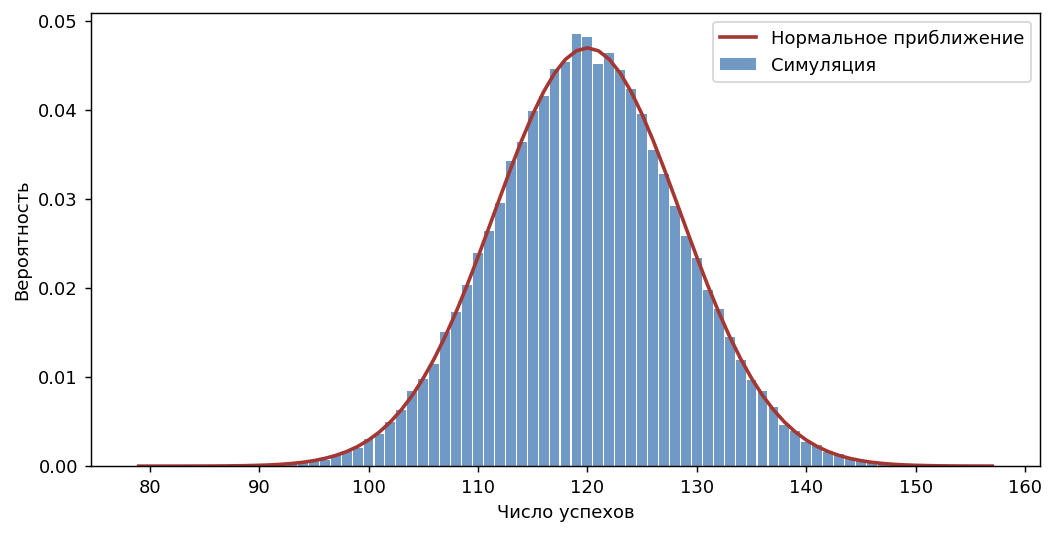

In [2]:
rng = np.random.default_rng(42)
n, p, repetitions = 300, 0.4, 100_000
s = rng.binomial(n, p, size=repetitions)

mu = n * p
sigma = sqrt(n * p * (1 - p))


def Phi(z):
    return (1 + erf(z / sqrt(2))) / 2


k = np.arange(s.min(), s.max() + 1)
frequencies = np.bincount(s, minlength=n + 1)[k] / repetitions
normal_masses = [
    Phi((j + 0.5 - mu) / sigma) - Phi((j - 0.5 - mu) / sigma)
    for j in k
]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(k, frequencies, width=0.9, color="#7199c5", label="Симуляция")
ax.plot(k, normal_masses, color="#a43732", linewidth=2, label="Нормальное приближение")
ax.set(xlabel="Число успехов", ylabel="Вероятность")
ax.legend()
plt.show()

Теперь сравним три способа вычислить $\mathbb P(110\le S\le130)$. При поправке на непрерывность объединяем все столбцы от 110 до 130 включительно, поэтому нормальные границы равны $109{,}5$ и $130{,}5$. Для точного ответа складываем биномиальные вероятности по целым $k$ от 110 до 130.

In [3]:
lower, upper = 110, 130
empirical = np.mean((lower <= s) & (s <= upper))
normal = Phi((upper + 0.5 - mu) / sigma) - Phi((lower - 0.5 - mu) / sigma)
exact = sum(comb(n, j) * p**j * (1 - p)**(n - j) for j in range(lower, upper + 1))

print(f"Симуляция:              {empirical:.5f}")
print(f"Нормальное приближение: {normal:.5f}")
print(f"Точная вероятность:     {exact:.5f}")

Симуляция:              0.78381
Нормальное приближение: 0.78408
Точная вероятность:     0.78416


Число испытаний $n$ задаёт распределение числа успехов в одном эксперименте. Число повторов определяет, насколько точно симуляция воспроизводит это распределение.

## 2. Оценка числа $\pi$ по случайным точкам

Впишем единичную окружность в квадрат $[-1,1]\times[-1,1]$. У равномерно выбранной в квадрате точки вероятность попасть внутрь круга равна отношению площадей.

$$
\mathbb P(X^2+Y^2\le1)=\frac{\pi}{4}.
$$

Обозначим через $M_m$ число попаданий среди первых $m$ независимых точек. Доля $M_m/m$ — среднее индикаторов попадания. По закону больших чисел она сходится к $\pi/4$, поэтому $\widehat{\pi}_m=4M_m/m$ сходится к $\pi$.

In [4]:
rng = np.random.default_rng(123)
N = 1_000_000
x, y = rng.uniform(-1, 1, size=(N, 2)).T
inside = x**2 + y**2 <= 1

m = np.arange(1, N + 1)
pi_estimates = 4 * np.cumsum(inside) / m

for count in (1_000, 10_000, 100_000, N):
    print(f"{count:>9} точек: {pi_estimates[count - 1]:.6f}")

     1000 точек: 3.180000
    10000 точек: 3.159600
   100000 точек: 3.140080
  1000000 точек: 3.141852


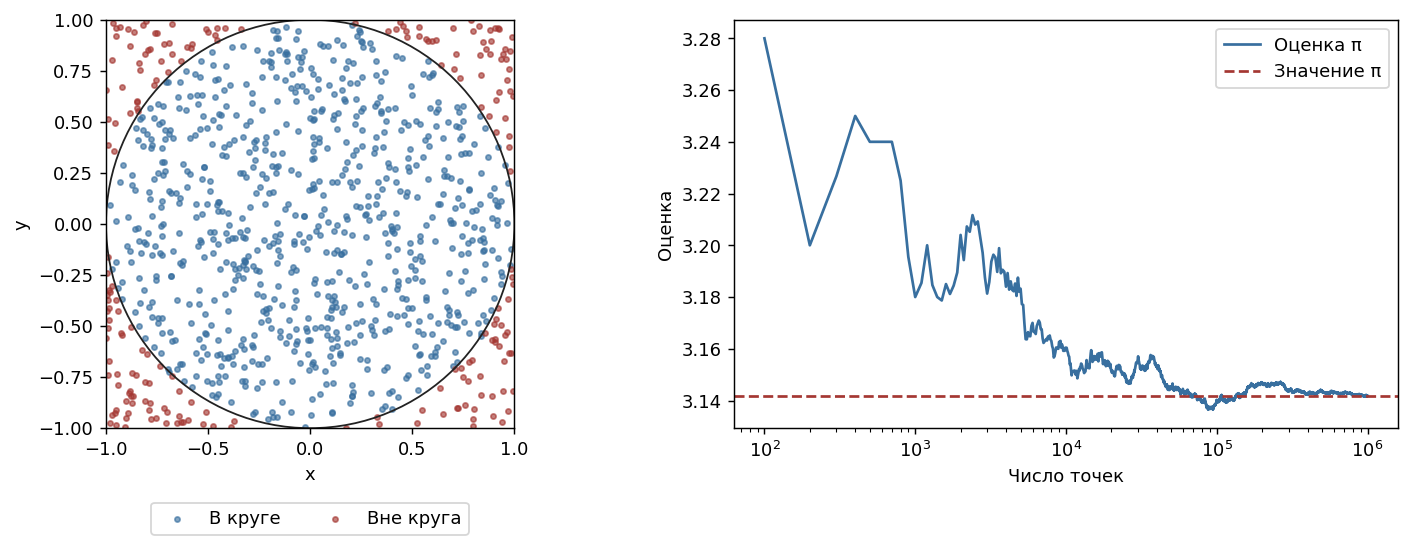

In [5]:
fig, (geometry, running) = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")

# На рисунке квадрата показываем только первую тысячу точек.
first = slice(0, 1_000)
for flag, color, label in [(True, "#386f9f", "В круге"), (False, "#a43732", "Вне круга")]:
    mask = inside[first] == flag
    geometry.scatter(x[first][mask], y[first][mask], s=8, alpha=0.63, color=color, label=label)
geometry.add_patch(plt.Circle((0, 0), 1, fill=False, edgecolor="#222222"))
geometry.set(xlim=(-1, 1), ylim=(-1, 1), aspect="equal", xlabel="x", ylabel="y")
geometry.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

running.semilogx(m[99::100], pi_estimates[99::100], color="#386f9f", label="Оценка π")
running.axhline(np.pi, color="#a43732", linestyle="--", label="Значение π")
running.set(xlabel="Число точек", ylabel="Оценка")
running.legend()
plt.show()

На правом графике видны колебания. Закон больших чисел объясняет сходимость доли попаданий, хотя при добавлении отдельных точек ошибка может временно вырасти. 